# Early Learning Support: Validation Benchmark

[Open in Colab](https://colab.research.google.com/github/Junghwan0516/early-learning-support/blob/main/02_model_comparison.ipynb)

**Stage 2 question:** Do consistency, recency, and weekly activity improve outreach ranking beyond total clicks?

Seven model families are compared under three predeclared configurations each. A low-activity rule may win. Random review is repeated 500 times as a reference and is not a fitted competitor. Three configurations per family do not imply equal compute cost.

Primary selection: validation Recall@10%, then average precision, family name and configuration index for deterministic remaining ties. At a fixed review budget, precision and recall rank methods identically. Test outcomes are not used for model fitting, selection, plots, or error analysis.

Ranking ties use one fixed, outcome-independent shuffled order shared across methods. SVM uses decision scores, not calibrated probabilities. MLP early stopping uses a training-only internal subset; this is an optimization convenience, not a chronological external validation.

In [1]:
from pathlib import Path
import urllib.request
import sys

repository_root = 'https://raw.githubusercontent.com/Junghwan0516/early-learning-support/main/'
for filename in ['els.py', 'prepare_data.py']:
    if not Path(filename).exists():
        with urllib.request.urlopen(repository_root + filename, timeout=60) as response:
            Path(filename).write_bytes(response.read())
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import els
els.style()

## 1. Split isolation

The original feature CSV includes repeat learners. Earlier splits take precedence. The final-test split is retained but not scored. All scaling is fitted within training-only pipelines.

In [2]:
df = els.load_data()
parts, split_audit = els.split_data(df)
display(split_audit)

,split,presentation,eligible_before_dedup,excluded_repeat_learners,rows,withdrawn,withdrawal_rate
0,train,2013B,1522,0,1522,269,0.176741
1,validation,2013J,1816,28,1788,233,0.130313
2,test,2014J,1724,39,1685,219,0.129970


## 2. Predeclared validation benchmark

Run the full benchmark, retaining all configurations and warnings rather than only the best result. Configuration details are written to `reports/benchmark_protocol.json` before fitting.

In [3]:
best, configurations, models, predictions, random_results = els.run_benchmark(parts)
display(best[['family','config','recall_at_10pct','precision_at_10pct',
              'average_precision','roc_auc','fit_seconds','warnings']])

,family,config,recall_at_10pct,precision_at_10pct,average_precision,roc_auc,fit_seconds,warnings
0,Logistic regression,2,0.175966,0.229050,0.178141,0.582492,0.003438,
1,KNN,2,0.171674,0.223464,0.161012,0.555864,0.003050,
2,Random forest,2,0.167382,0.217877,0.170265,0.571873,0.316075,
3,Gradient boosting,2,0.158798,0.206704,0.158126,0.566332,0.223545,
4,Low-activity rule,0,0.154506,0.201117,0.165343,0.569268,0.000000,
5,Decision tree,2,0.137339,0.178771,0.148407,0.534896,0.005577,
6,MLP,0,0.115880,0.150838,0.130495,0.481094,0.034005,
7,SVM,0,0.094421,0.122905,0.146601,0.556007,0.025193,


## 3. Performance, ranking curves, and computation

The selected configuration of each family is shown. Curves are descriptive validation diagnostics and do not replace the predefined 10% selection criterion. Timing is specific to the execution environment, not a hardware-independent benchmark.

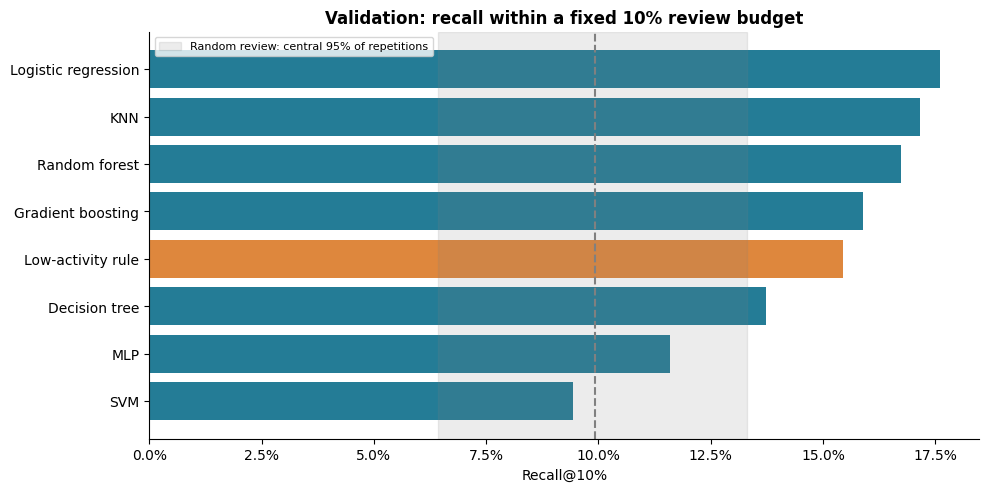

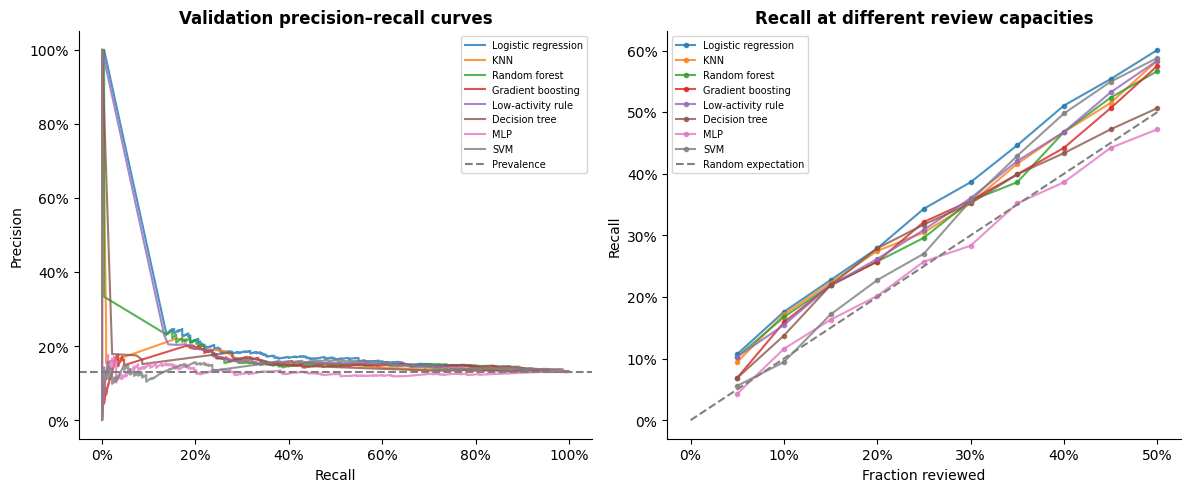

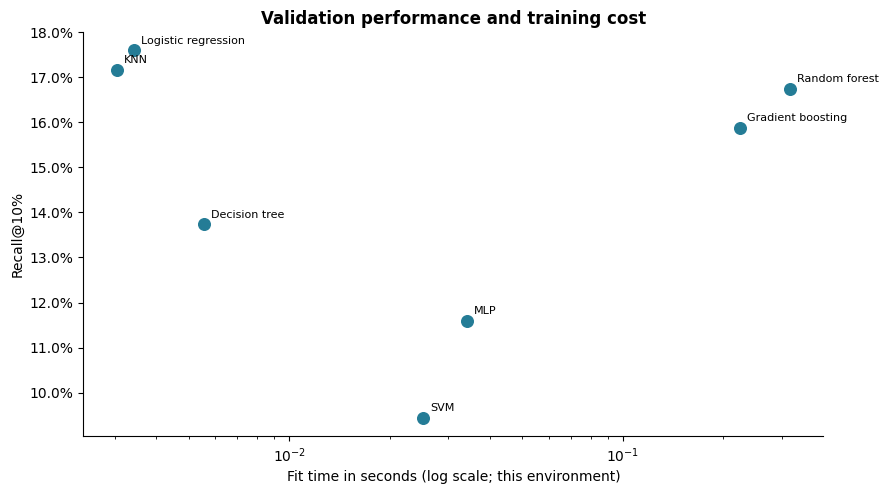

In [4]:
els.plot_benchmark(parts, best, predictions, random_results)

## 4. Feature ablation

Two fixed model configurations compare four feature sets. This isolates representation changes more clearly than comparing different models and features at the same time. Alternative sums are deterministic combinations of weekly features, not independent new measurements. This ablation is diagnostic, not an additional search for the final-test winner.

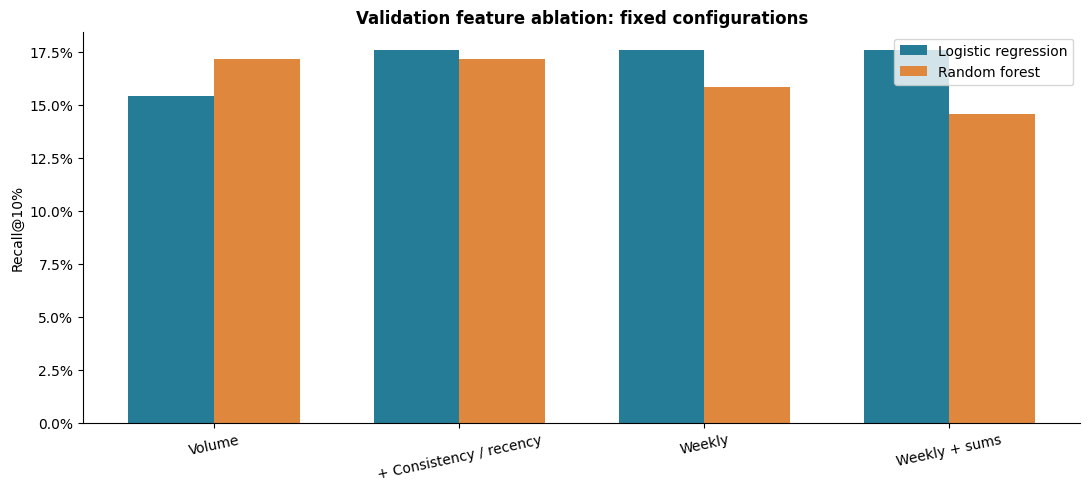

,family,feature_set,recall_at_10pct,average_precision
0,Logistic regression,Volume only,0.154506,0.165343
1,Logistic regression,Volume + consistency + recency,0.175966,0.178452
2,Logistic regression,Weekly representation,0.175966,0.178122
3,Logistic regression,Weekly + alternative sums,0.175966,0.178127
4,Random forest,Volume only,0.171674,0.151669
5,Random forest,Volume + consistency + recency,0.171674,0.167811
6,Random forest,Weekly representation,0.158798,0.164063
7,Random forest,Weekly + alternative sums,0.145923,0.164162


In [5]:
ablation = els.feature_ablation(parts)
display(ablation[['family','feature_set','recall_at_10pct','average_precision']])

## 5. Error profiles and uncertainty

Error groups compare captured withdrawals, missed withdrawals, and reviewed non-withdrawals. These are aggregate feature profiles, not explanations of an individual's decision.

The paired bootstrap resamples validation learners and recomputes each method's review ranking. Models are held fixed. The interval does not account for selection from many configurations and must not be presented as unbiased final-test evidence. An interval crossing zero does not establish a clear improvement over the rule.

{'selected_method': 'Logistic regression / 2', 'difference': 0.02145922746781115, 'lower': -0.004237738910926783, 'upper': 0.04291971231223177, 'note': 'Exploratory conditional-on-fitted-model interval; model selection is not accounted for. Not final-test evidence.'}


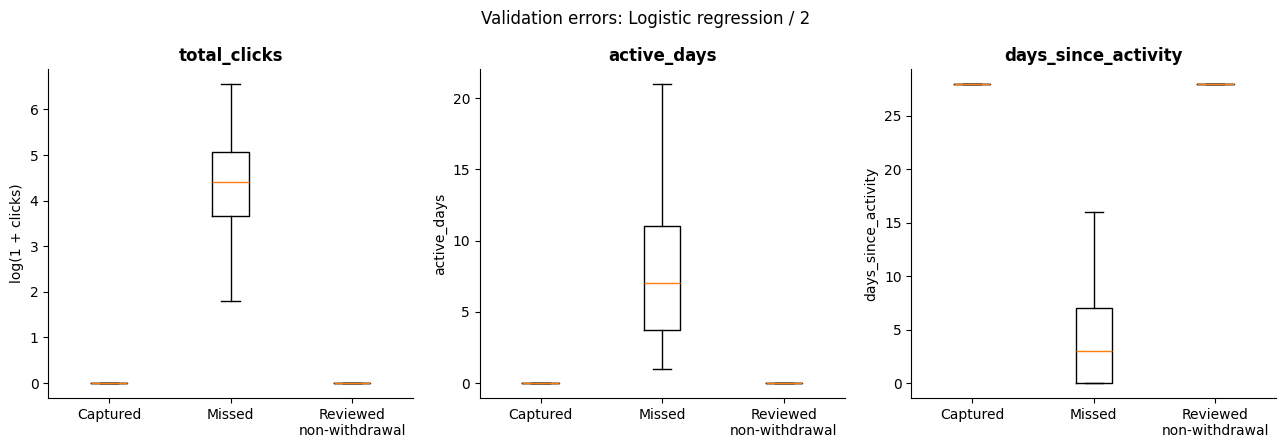

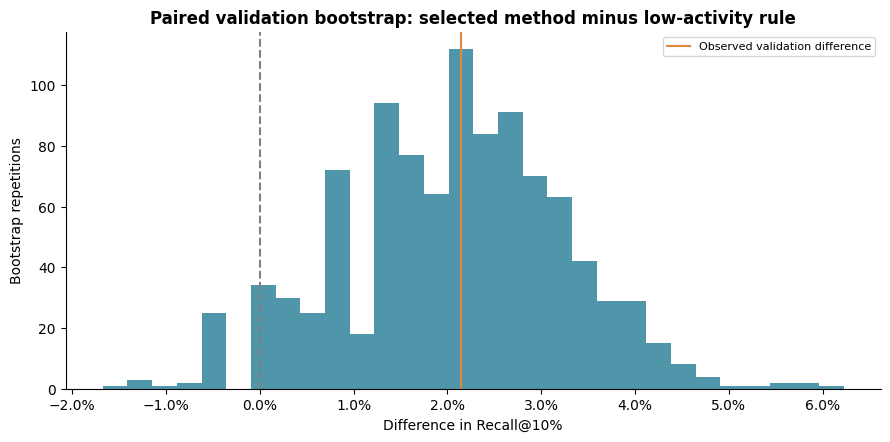

,total_clicks,active_days,days_since_activity,learners
review_outcome,,,,
Captured withdrawal,0.0,0.0,28.0,41
Missed withdrawal,82.0,7.0,3.0,192
Reviewed non-withdrawal,0.0,0.0,28.0,138
Unreviewed non-withdrawal,95.0,8.0,2.0,1417


In [6]:
error_groups, bootstrap_result = els.validation_diagnostics(parts, best, predictions)
display(error_groups)
print(bootstrap_result)

## Validation findings

The validation-selected method is **Logistic regression / 2**, capturing 41 of 233 later withdrawals within a budget of 179 reviewed learners. Recall@10% is **17.6%**, precision@10% **22.9%**, and average precision **0.178**.

The selected method minus the low-activity rule has an observed validation recall difference of 2.1%, with an exploratory paired-bootstrap interval of -0.4% to 4.3%. This interval is conditional on the fitted methods and does not account for configuration selection. It is not a final-test performance claim.

MLP early stopping, finite configuration budgets, and seed dependence limit universal model comparisons. Warnings, all configurations, feature ablations, and execution versions are retained in `reports/`.

## 6. Freeze the validation-selected method

The selection is recorded before final evaluation. Do not rerun tuning after inspecting final-test performance. All present results remain validation estimates, potentially optimistic after model selection.

In [7]:
import json
import platform
import sklearn

selection = best.iloc[0]
frozen_selection = {
    'method': selection['method'],
    'family': selection['family'],
    'config': int(selection['config']),
    'features': els.FEATURES,
    'validation_recall_at_10pct': float(selection['recall_at_10pct']),
    'validation_average_precision': float(selection['average_precision']),
    'test_evaluated': False,
}
Path('reports/frozen_selection.json').write_text(json.dumps(frozen_selection, indent=2))
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit_learn': sklearn.__version__}
Path('reports/environment.json').write_text(json.dumps(versions, indent=2))
print(frozen_selection)

{'method': 'Logistic regression / 2', 'family': 'Logistic regression', 'config': 2, 'features': ['clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4', 'active_days', 'days_since_activity', 'last_week_change', 'total_clicks'], 'validation_recall_at_10pct': 0.1759656652360515, 'validation_average_precision': 0.17814114612573478, 'test_evaluated': False}
